# Creating custom Linear Regression Class

In [1]:
class LR:
    def __init__(self):
        self.m = None
        self.b = None
    
    def fit(self, x_train, y_train):
        num = 0
        den = 0
        for i in range(x_train.shape[0]):
            num = num + ((x_train[i] - x_train.mean()) * (y_train[i] - y_train.mean()))
            den = den + ((x_train[i] - x_train.mean()) * (x_train[i] - x_train.mean()))
        self.m = num / den
        self.b = y_train.mean() - (self.m * x_train.mean())
        print(self.m)
        print(self.b)

    def predict(self, x_test):
        return self.m * x_test + self.b

In [2]:
import numpy as np
import pandas as pd

In [3]:
df = pd.read_csv("../dataset/raw/Salary_dataset.csv")
df.head()

,Unnamed: 0,YearsExperience,Salary
0,0,1.2,39344.0
1,1,1.4,46206.0
2,2,1.6,37732.0
3,3,2.1,43526.0
4,4,2.3,39892.0


Text(0, 0.5, 'Salary')

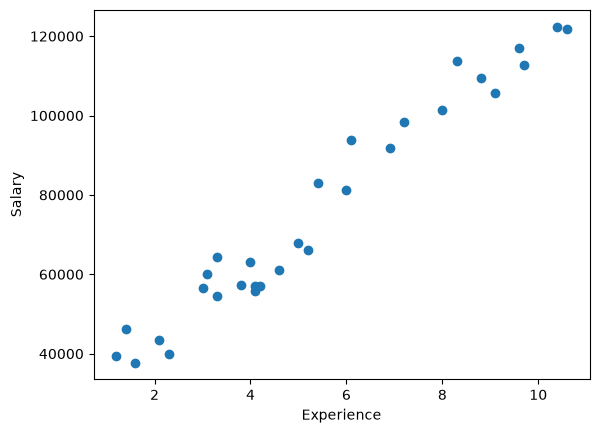

In [4]:
import matplotlib.pyplot as plt
plt.scatter(x=df['YearsExperience'], y=df['Salary'])
plt.xlabel("Experience")
plt.ylabel("Salary")

In [5]:
x = df.iloc[:, 1].values
y = df.iloc[:, 2].values

In [6]:
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.1, random_state=42)

In [7]:
x_train.shape[0]

27

In [8]:
lr = LR()
lr.fit(x_train, y_train)

9371.313117259971
25161.887090887423


Text(0, 0.5, 'Salary')

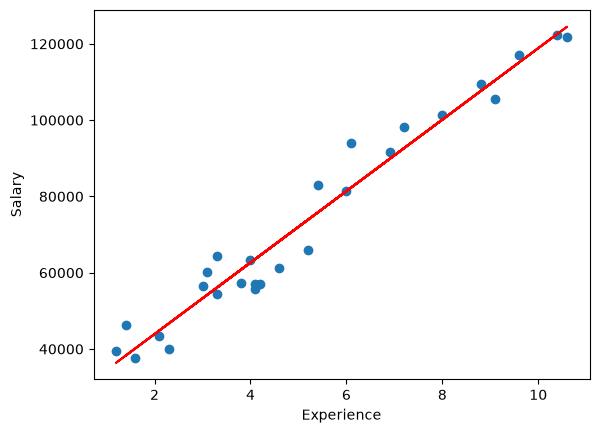

In [9]:
plt.scatter(x=x_train, y=y_train)
plt.plot(x_train, lr.predict(x_train), color="red")
plt.xlabel("Experience")
plt.ylabel("Salary")

In [10]:
predicted_salary = lr.predict(x_test)

In [11]:
print(f"Original: {y_test}")
print(f"Predicted: {predicted_salary}")

Original: [112636.  67939. 113813.]
Predicted: [116063.62432831  72018.45267719 102943.78596415]


## Metrics Calculation

In [12]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
print(f"MAE: {mean_absolute_error(y_test, predicted_salary)}")
print(f"MSE: {mean_squared_error(y_test, predicted_salary)}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, predicted_salary))}")
print(f"R2 Score: {r2_score(y_test, predicted_salary)}")

r2 = r2_score(y_test, predicted_salary)

MAE: 6125.4303471170815
MSE: 48843452.14621687
RMSE: 6988.8090649421
R2 Score: 0.8928775350863083


In [13]:
# Adjusted R2 Score
print(1 - ((1 - r2) * (27 - 1) / (27 - 1 -  1)))

0.8885926364897606
